In [ ]:
'''
Factor Analysis

By Anita Taylor

Date:  17/10/2023
'''

In [ ]:
'''
Sources:
https://www.datasklr.com/principal-component-analysis-and-factor-analysis/factor-analysis
https://www.earthinversion.com/geophysics/exploratory-factor-analysis/

https://www.datacamp.com/tutorial/introduction-factor-analysis
https://www.analyticsvidhya.com/blog/2020/10/dimensionality-reduction-using-factor-analysis-in-python/

https://www.kaggle.com/code/harrimansaragih/factor-analysis-of-airline-passenger-satisfaction
'''

In [ ]:
'''
Questions:


Should I use Promax not varimax rotation?  Due to slight correlation and large dataset?

'''

In [7]:
!pip install factor_analyzer

     ---------------------------------------- 0.0/42.5 kB ? eta -:--:--
     ---------------------------------------- 42.5/42.5 kB ? eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Obtaining dependency information for pre-commit from https://files.pythonhosted.org/packages/6c/75/526915fedf462e05eeb1c75ceaf7e3f9cde7b5ce6f62740fe5f7f19a0050/pre_commit-3.5.0-py2.py3-none-any.whl.metadata
  Obtaining dependency information for cfgv>=2.0.0 from https://files.pythonhosted.org/packages/c5/55/51844dd50c4fc7a33b653bfaba4c2456f06955289ca770a5dbd5fd267374/cfgv-3.4.0-py2.py3-none-any.whl.metadata
  Obtaining dependency information for identify>=1.0.0 from https://files.pythonhosted.org/packages/46/02/2581c3

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler
import seaborn as sns

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from factor_analyzer.factor_analyzer import calculate_kmo


In [4]:
'''
Input
'''
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number', 'year_month','Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology']
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')

DropDF1c = ['OBSWELL']
Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')



In [5]:
#Use a local Cartesian conversion to account for distance given it is very 'flat'.  Also should I reference Vancouver as the reference points?  They think they are the center of the world anyway

# Calculate the reference point
ref_latitude = Datat['LATITUTE'].mean()
ref_longitude = Datat['LONGITUDE'].mean()

# Convert the differences in latitude and longitude from the reference point into distances
Datat['x'] = (Datat['LONGITUDE'] - ref_longitude) * (111.412 * np.cos(np.radians(ref_latitude)) - 0.0935 * np.cos(3 * np.radians(ref_latitude)))
Datat['y'] = (Datat['LATITUTE'] - ref_latitude) * 111.132

DropDF2b = ['LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF2b, axis=1, errors='ignore')

#Start encoding it.  Will Finish it later
one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer')
Datat = pd.concat([Datat, one_hot_df], axis=1)

#Decided to keep reference points the same
Datat['DATE'] = pd.to_datetime(Datat['DATE'])
Datawithtime = Datat.copy()

#Used "Time since event" - months since the first sampling time.  As this is sequencial, it has to be calculated in subsequent dataframes
Datat['Months_Since_First_Sample'] = ((Datat['DATE'] - Datat['DATE'].min()) / np.timedelta64(1, 'M')).round()
DropDF2a = ['DATE']
Datat = Datat.drop(DropDF2a, axis=1, errors='ignore')



In [69]:
Datat.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T',
       'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group', 'x', 'y', 'Aquifer_1', 'Aquifer_2', 'Aquifer_3',
       'Months_Since_First_Sample'],
      dtype='object')

In [70]:
Datat.shape

(985, 29)

In [6]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''
def replace_loweroutliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = cleaned_dataset.loc[cleaned_dataset[col]]
    return cleaned_dataset
                                                                                               
numeric_cols1a = ['U--T']
cleaned_dataset_array1a = replace_loweroutliers_with_iqr(Datat[numeric_cols1a], 1.5)
Datat[numeric_cols1a] = cleaned_dataset_array1a                                                    
                                                                   
                                                                                               
def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',  'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
#Numeric_cols1a = ['Alkalinity Total 4.5', 'Hardness Total (T)','Residue Filterable 1.0u']
cleaned_dataset_array1 = replace_outliers_with_iqr(Datat[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[outliers, col] = upper_threshold
        outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[outliers, col] = lower_threshold
    return cleaned_dataset


KeyError: "None of [Float64Index([   1e-06,    1e-06,  0.00054, 0.000581, 0.000468, 0.000486,\n              0.000524, 0.000514, 0.000566, 0.000571,\n              ...\n              0.027475,  0.00137, 0.000621, 0.000565, 0.000831, 0.000979,\n              0.000666,  2.7e-05,    2e-06,    1e-05],\n             dtype='float64', length=985)] are in the [index]"

In [7]:
'''
Scaling

Source:
https://scikit-learn.org/stable/modules/preprocessing.html
https://stats.stackexchange.com/questions/402470/how-can-i-use-scaling-and-log-transforming-together

https://stackoverflow.com/questions/60998512/how-to-scale-all-columns-except-last-column
https://stackoverflow.com/questions/62997793/apply-standarization-to-all-columns-except-one-in-pandas
'''

from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT' , 'Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u']
# Apply the transformation to the specified columns
Datat[cols_to_transform] = pt.fit_transform(Datat[cols_to_transform])

In [76]:
'''
encoding 

# encode this to numbers instead.   Make it a different dataset
source:
'''
DatatHot = Datat.drop(columns='Aquifer Group')
DatatHot.shape

(985, 28)

In [37]:
'''
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
Datat[cols_to_transform] = scaler.fit_transform(Datat[cols_to_transform])
'''

'\nfrom sklearn.preprocessing import MinMaxScaler\nscaler = MinMaxScaler()\nDatat[cols_to_transform] = scaler.fit_transform(Datat[cols_to_transform])\n'

In [77]:
'''
SWI, Drought, Flood, Heatwave
'''

DatatSWI =Datawithtime[(Datawithtime['Chlrid:D'] > 150) | (Datawithtime['Specific Conductance'] > 100)]
DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatSWI = DatatSWI.drop(DropDF2a, axis=1, errors='ignore')

DatatDrought = Datawithtime[(Datawithtime['FD'] < 0)]
DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatDrought = DatatDrought.drop(DropDF2a, axis=1, errors='ignore')

DatatFlood = Datawithtime[(Datawithtime['FD'] > 0)]
DatatFlood['Months_Since_First_Sample'] = ((DatatFlood['DATE'] - DatatFlood['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatFlood = DatatFlood.drop(DropDF2a, axis=1, errors='ignore')

DatatHW = Datawithtime[(Datawithtime['HW'] > 0)]
DatatHW['Months_Since_First_Sample'] = ((DatatHW['DATE'] - DatatHW['DATE'].min()) / np.timedelta64(1, 'M')).round()
DatatHW = DatatHW.drop(DropDF2a, axis=1, errors='ignore')


cleaned_dataset_array2 = replace_outliers_with_iqr(DatatLatLong[numeric_cols1], 1.5)
DatatLatLong[numeric_cols1] = cleaned_dataset_array2
DatatLatLong[cols_to_transform] = pt.fit_transform(DatatLatLong[cols_to_transform])  
                                                           
#numeric_cols1 = ['pH', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'K--T',  'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT']
cleaned_dataset_array2i = replace_outliers_with_iqr(DatatSWI[numeric_cols1], 1.5)
DatatSWI[numeric_cols1] = cleaned_dataset_array2i
DatatSWI[cols_to_transform] = pt.fit_transform(DatatSWI[cols_to_transform])

cleaned_dataset_array2ii = replace_outliers_with_iqr(DatatDrought[numeric_cols1], 1.5)
DatatDrought[numeric_cols1] = cleaned_dataset_array2ii
DatatDrought[cols_to_transform] = pt.fit_transform(DatatDrought[cols_to_transform])
                                                           
cleaned_dataset_array2iii = replace_outliers_with_iqr(DatatFlood[numeric_cols1], 1.5)
DatatFlood[numeric_cols1] = cleaned_dataset_array2iii
DatatFlood[cols_to_transform] = pt.fit_transform(DatatFlood[cols_to_transform])

cleaned_dataset_array2iv = replace_outliers_with_iqr(DatatHW[numeric_cols1], 1.5)
DatatHW[numeric_cols1] = cleaned_dataset_array2iv
DatatHW[cols_to_transform] = pt.fit_transform(DatatHW[cols_to_transform])
DatatHW.columns

#Finish Encoding

DatatSWIHot = DatatSWI.drop(columns='Aquifer Group')
DatatDroughtHot = DatatDrought.drop(columns='Aquifer Group')
DatatFloodHot = DatatFlood.drop(columns='Aquifer Group')
DatatHWHot = DatatHW.drop(columns='Aquifer Group')


C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_20212\3490134751.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatSWI['Months_Since_First_Sample'] = ((DatatSWI['DATE'] - DatatSWI['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_20212\3490134751.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DatatDrought['Months_Since_First_Sample'] = ((DatatDrought['DATE'] - DatatDrought['DATE'].min()) / np.timedelta64(1, 'M')).round()
C:\Users\Anita Taylor

KeyError: "['Alkalinity Total 4.5', 'Hardness Total (T)', 'Residue Filterable 1.0u'] not in index"

In [ ]:
#Fix this 

DropDF2a = ['DATE', 'OBSWell']

DatatSWILL= DatatSWI.drop(DropDF2a, axis=1, errors='ignore')
DatatDroughtLL= DatatDrought.drop(DropDF2a, axis=1, errors='ignore')
DatatFloodLL= DatatFlood.drop(DropDF2a, axis=1, errors='ignore')
DatatHWLL= DatatHW.drop(DropDF2a, axis=1, errors='ignore')


one_hot_df = pd.get_dummies(DatatHot['Aquifer Group'], prefix='Aquifer')
DatatHot = pd.concat([DatatHot, one_hot_df], axis=1)
DatatHot.drop(columns='Aquifer Group', inplace=True)
DatatHot.head()

DropDF3a = ['LONGITUDE', 'LATITUTE', 'DATE', 'year_month', 'OBSWELL']
DatatSWIND= DatatSWI.drop(DropDF3a, axis=1, errors='ignore')
DatatDroughtND= DatatDrought.drop(DropDF3a, axis=1, errors='ignore')
DatatFloodND= DatatFlood.drop(DropDF3a, axis=1, errors='ignore')
DatatHWND= DatatHW.drop(DropDF3a, axis=1, errors='ignore')
DatatSWIND.head()

In [78]:
DatatHot.dtypes

Alkalinity Total 4.5         float64
As-T                         float64
Ca-T                         float64
Chlrid:D                     float64
Fe-T                         float64
Mn-T                         float64
N.Kjel:T                     float64
P--T                         float64
Pb-T                         float64
Residue Filterable 1.0u      float64
Specific Conductance         float64
Sulfat:D                     float64
pH                           float64
Hardness Total (T)           float64
K--T                         float64
U--T                         float64
PRECIPITATION                float64
MIN_TEMP                     float64
MAX_TEMP                     float64
FD                           float64
HW                           float64
MT                           float64
x                            float64
y                            float64
Aquifer_1                      uint8
Aquifer_2                      uint8
Aquifer_3                      uint8
M

In [63]:
DatatHot.head()

,As-T,Ca-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,Specific Conductance,Sulfat:D,...,MAX_TEMP,FD,HW,MT,x,y,Aquifer_1,Aquifer_2,Aquifer_3,Months_Since_First_Sample
0,1.677243,1.781862,1.517344,1.104648,0.387082,0.657125,0.877092,1.618282,1.713688,1.028585,...,0.903721,0.598895,-2.746333,-1.278721,201.457703,87.469175,1,0,0,126.0
1,1.677243,1.781862,1.517344,1.328472,0.510849,-1.199072,1.033549,1.728926,1.676435,1.118564,...,1.437158,-0.044213,-0.604191,-0.193420,201.457703,87.469175,1,0,0,197.0
2,1.223570,1.781862,1.517344,1.396059,0.520657,0.461012,0.969606,-0.583253,1.713688,1.068384,...,0.821059,0.274140,1.114867,0.355661,201.457703,87.469175,1,0,0,243.0
3,1.256337,1.781862,1.517344,1.208605,0.386002,0.228797,0.958509,-0.639051,1.713688,1.033638,...,-0.512327,1.620062,-0.128731,1.133494,201.457703,87.469175,1,0,0,248.0
4,1.069170,1.781862,1.517344,0.750916,0.370790,0.096652,0.474990,-0.641224,1.713688,1.182179,...,1.704315,0.230558,0.704730,0.245101,201.457703,87.469175,1,0,0,294.0


In [79]:
#CHECK ADEQUACY .
#Bartlett.  Over 5 samples per variable so not trustworthy 
#p-value should be 0 (statistically sig.)
# Select only the continuous columns
continuous_columns = DatatHot.columns[DatatHot.dtypes == 'float64']
DatatContinuous = DatatHot[continuous_columns]

# Run the test on the continuous data
chi_square_value, p_value = calculate_bartlett_sphericity(DatatContinuous)
print(chi_square_value, p_value)


16106.280064096878 0.0


In [80]:
from factor_analyzer.factor_analyzer import calculate_kmo

kmo_all,kmo_model=calculate_kmo(DatatContinuous)

print('Overall MSA:', kmo_model)
print('\nMSA for each variable:\n', kmo_all)

Overall MSA: 0.7282817413555475

MSA for each variable:
 [0.91474239 0.82288145 0.77512266 0.73462833 0.69341863 0.63067284
 0.76464771 0.5806161  0.66407285 0.88391872 0.83847125 0.92519092
 0.75329049 0.78864612 0.83402094 0.90363082 0.69260399 0.44098686
 0.45083055 0.39868347 0.4189853  0.34115715 0.56518938 0.66920371
 0.71437611]


In [81]:
DatatHot.shape

(985, 28)

In [86]:
from factor_analyzer import FactorAnalyzer

# Instantiate the factor analyzer
fa = FactorAnalyzer(n_factors=25, rotation=None)

# Fit the factor analyzer to the data
fa.fit(DatatHot)

# Get the eigenvalues
ev, v = fa.get_eigenvalues()
print('Eigenvalues:\n', ev)
count = sum(1 for i in ev if i > 1)
print(count)
big_evs = sum(i for i in ev if i > 1)
total_evs = sum(ev)
print(big_evs)
print(float(big_evs/total_evs))

Eigenvalues:
 [ 6.11721604e+00  3.14769159e+00  2.62200410e+00  2.12459489e+00
  1.99786879e+00  1.66299554e+00  1.28393157e+00  1.20471123e+00
  1.06083560e+00  8.91745132e-01  8.18109287e-01  7.36669092e-01
  6.72420042e-01  5.78442433e-01  4.46969251e-01  3.98175555e-01
  3.95121518e-01  3.32755838e-01  2.97200064e-01  2.87485810e-01
  2.21616598e-01  2.05497029e-01  1.82905134e-01  1.48529771e-01
  6.80318980e-02  5.42668648e-02  4.22093276e-02 -1.87536823e-15]
9
21.221849354513566
0.7579231912326273


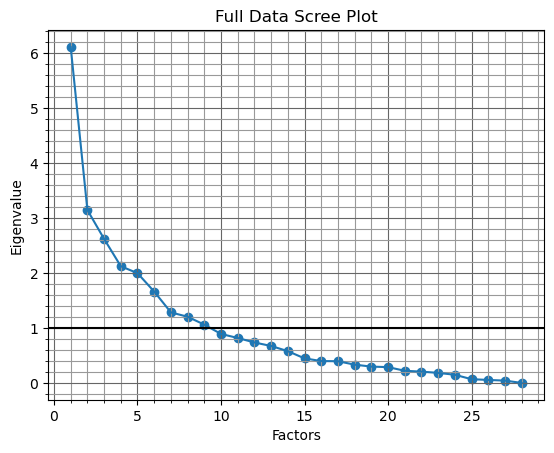

In [90]:
# Create scree plot using matplotlib
plt.scatter(range(1, DatatHot.shape[1]+1), ev)
plt.plot(range(1, DatatHot.shape[1]+1), ev)
plt.title('Full Data Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.axhline(y=1, c='k')

# Major grid lines
plt.grid(color='#666666', linestyle='-')

# Show the minor grid lines with very faint and almost transparent grey lines
plt.minorticks_on()
plt.grid(which='minor', color='#999999', linestyle='-')

plt.show()
#visualisation of the 9 eigenvalues > 1.
plt.savefig('Figures/1stfulldatascree.png')

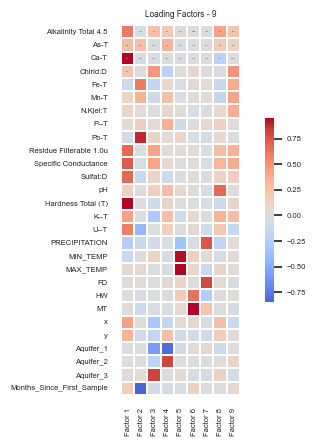

In [93]:
fa2 = FactorAnalyzer(9, rotation="varimax")
fa2.fit(DatatHot)
x_labels = ['Factor ' + str(i) for i in range(1,count+1)]
y_labels = DatatHot.columns.tolist()
sns.set(font_scale=0.5)
plt.title('Loading Factors - ' + str(count))
load = sns.heatmap(fa2.loadings_,cmap="coolwarm", xticklabels = x_labels, yticklabels = y_labels, center=0, square=True, linewidths=.2,cbar_kws={"shrink": 0.5}, annot = True, annot_kws={"fontsize":1})
plt.savefig('Figures/VarimaxFAEG9fulldata.png')

In [95]:
FAmatrixFull9 = pd.DataFrame(fa2.loadings_, index = list(DatatHot.columns), columns = ['Factor 1', 'Factor 2', 'Factor 3', 'Factor 4', 'Factor 5', 'Factor 6', 'Factor 7', 'Factor 8', 'Factor 9'])
FAmatrixFull9.to_csv("Stats/FAmatrixFull9.csv")
FAmatrixFull9.head()

,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9
Alkalinity Total 4.5,0.610885,-0.043961,0.265625,0.219879,0.048148,0.008756,-0.027942,0.435505,0.250072
As-T,0.289810,0.285456,-0.038789,0.343466,-0.023377,-0.025931,0.014077,0.168830,0.125750
Ca-T,0.946411,-0.051258,-0.025767,0.009220,-0.018025,-0.009013,-0.029429,-0.217566,0.008220
Chlrid:D,0.244668,0.012497,0.477078,-0.234921,0.029239,0.083510,0.015933,-0.039094,0.499833
Fe-T,-0.104672,0.598999,-0.179177,0.091283,-0.032676,0.059033,0.039051,-0.121549,0.377563


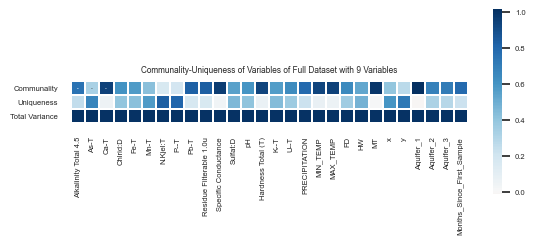

In [97]:
var_check = np.vstack((fa2.get_communalities(), fa2.get_uniquenesses(),np.array(fa2.get_communalities() + fa2.get_uniquenesses()))).tolist()
y_labels = ['Communality','Uniqueness', 'Total Variance']
x_labels = DatatHot.columns.tolist()
sns.set(font_scale=0.5)
plt.title('Communality-Uniqueness of Variables of Full Dataset with 9 Variables')
load = sns.heatmap(var_check,cmap="RdBu", xticklabels = x_labels, yticklabels = y_labels, center=0, square=True, linewidths=.2,cbar_kws={"shrink": 0.5}, annot = True, annot_kws={"fontsize":1})
plt.savefig('Figures/CommunityUniquenessTotalVarFAEG9fulldata.png')

In [ ]:


# Create factor analysis object and perform factor analysis using 5 factors
fa = FactorAnalyzer()
fa.analyze(df, 5, rotation="varimax")
fa.loadings

In [ ]:
# Create factor analysis object and perform factor analysis
fa = FactorAnalyzer()
fa.analyze(df, 17, rotation=None)
# Check Eigenvalues
ev, v = fa.get_eigenvalues()
ev

In [ ]:
# Create scree plot using matplotlib
plt.scatter(range(1,df.shape[1]+1),ev.values)
plt.plot(range(1,df.shape[1]+1),ev.values)
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.axhline(y=1,c='k')


In [ ]:
# Create factor analysis object and perform factor analysis
fa = FactorAnalyzer()
fa.analyze(df, 6, rotation="varimax")
fa.loadings

In [ ]:
import numpy as np
Z=np.abs(fa.loadings)
fig, ax = plt.subplots()
c = ax.pcolor(Z)
fig.colorbar(c, ax=ax)
ax.set_yticks(np.arange(fa.loadings.shape[0])+0.5, minor=False)
ax.set_xticks(np.arange(fa.loadings.shape[1])+0.5, minor=False)
ax.set_yticklabels(fa.loadings.index.values)
ax.set_xticklabels(fa.loadings.columns.values)
plt.show()

In [ ]:
# Create factor analysis object and perform factor analysis using 5 factors
fa = FactorAnalyzer()
fa.analyze(df, 5, rotation="varimax")
fa.loadings

In [ ]:
Z=np.abs(fa.loadings)
fig, ax = plt.subplots()
c = ax.pcolor(Z)
fig.colorbar(c, ax=ax)
ax.set_yticks(np.arange(fa.loadings.shape[0])+0.5, minor=False)
ax.set_xticks(np.arange(fa.loadings.shape[1])+0.5, minor=False)
ax.set_yticklabels(fa.loadings.index.values)
ax.set_xticklabels(fa.loadings.columns.values)
plt.show()

In [ ]:
# Get variance of each factors
fa.get_factor_variance()

In [ ]:
# Communality
communality = Series(np.square(fa.components_.T).sum(axis=1), index=food.columns)
communality.plot(
    kind="bar",
    ylabel="communality"
)

#Uniqueness is 1- communality 

In [ ]:
'''
Residue matric

Source:
https://www.geo.fu-berlin.de/en/v/soga-py/Advanced-statistics/Multivariate-Approaches/Factor-Analysis/A-Simple-Example-of-Factor-Analysis-in-Python/index.html
'''

# the word 'lambda' is reserved for a python-operator, so we use the underscore at the end
lambda_ = fa.components_
psi = np.diag(uniqueness)
s = np.corrcoef(np.transpose(X))
sigma = np.matmul(lambda_.T, lambda_) + psi
residuals = (s - sigma)

x = plt.axes()
im = ax.imshow(residuals, cmap="RdBu_r", vmin=-1, vmax=1)
ax.tick_params(axis="x", bottom=False, labelbottom=False, top=True, labeltop=True)
ax.set_xticks(range(5))
ax.set_xticklabels(food.columns)
ax.set_yticks(range(5))
ax.set_yticklabels(food.columns)
for (i,j), z in np.ndenumerate(residuals):
    ax.text(j, i, str(z.round(3)), ha="center", va="center")

fig.colorbar(im, ax=ax, location='right')
ax.set_title("FA residual matrix")
plt.tight_layout()

In [ ]:
'''
Salt Water Intrusion
'''

#CHECK ADEQUACY .
#Bartlett.  Over 5 samples per variable so not trustworthy 
#p-value should be 0 (statistically sig.)
# Select only the continuous columns
continuous_columnsSWI = DatatSWI.columns[DatatSWI.dtypes == 'float64']
DatatContinuousSWI = DatatSWI[continuous_columnsSWI]

# Run the test on the continuous data
chi_square_value, p_value = calculate_bartlett_sphericity(DatatContinuousSWI)
print(chi_square_value, p_value)


In [ ]:
from factor_analyzer.factor_analyzer import calculate_kmo

kmo_allswi,kmo_modelSWI=calculate_kmo(DatatContinuousSWI)

print('Overall MSA:', kmo_modelSWI)
print('\nMSA for each variable:\n', kmo_allSWI)

In [ ]:
'''
Drought
'''

#CHECK ADEQUACY .
#Bartlett.  Over 5 samples per variable so not trustworthy 
#p-value should be 0 (statistically sig.)
# Select only the continuous columns
continuous_columnsDrought = DatatDrought.columns[DatatDrought.dtypes == 'float64']
DatatContinuousDrought = DatatDrought[continuous_columnsDrought]

# Run the test on the continuous data
chi_square_value, p_value = calculate_bartlett_sphericity(DatatContinuousDrought)
print(chi_square_value, p_value)


In [ ]:
from factor_analyzer.factor_analyzer import calculate_kmo

kmo_allswi,kmo_modelSWI=calculate_kmo(DatatContinuousSWI)

print('Overall MSA:', kmo_modelSWI)
print('\nMSA for each variable:\n', kmo_allSWI)

In [ ]:
'''
Temp
'''

In [ ]:
# Create factor analysis object and perform factor analysis
fa = FactorAnalyzer()
fa.analyze(df, 7, rotation=None)
# Check Eigenvalues
ev, v = fa.get_eigenvalues()
ev

In [ ]:
# Create scree plot using matplotlib
plt.scatter(range(1,df.shape[1]+1),ev.values)
plt.plot(range(1,df.shape[1]+1),ev.values)
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.axhline(y=1,c='k')


In [ ]:
# Create factor analysis object and perform factor analysis
fa = FactorAnalyzer()
fa.analyze(df, 6, rotation="varimax")
fa.loadings

In [ ]:
import numpy as np
Z=np.abs(fa.loadings)
fig, ax = plt.subplots()
c = ax.pcolor(Z)
fig.colorbar(c, ax=ax)
ax.set_yticks(np.arange(fa.loadings.shape[0])+0.5, minor=False)
ax.set_xticks(np.arange(fa.loadings.shape[1])+0.5, minor=False)
ax.set_yticklabels(fa.loadings.index.values)
ax.set_xticklabels(fa.loadings.columns.values)
plt.show()

In [ ]:
# Get variance of each factors
fa.get_factor_variance()

#print(pd.DataFrame(fa.get_factor_variance(),index=['Variance','Proportional Var','Cumulative Var']))


In [ ]:
# Communality
communality = Series(np.square(fa.components_.T).sum(axis=1), index=food.columns)
communality.plot(
    kind="bar",
    ylabel="communality"
)

#Uniqueness is 1- communality 

In [ ]:
'''
Residue matric

Source:
https://www.geo.fu-berlin.de/en/v/soga-py/Advanced-statistics/Multivariate-Approaches/Factor-Analysis/A-Simple-Example-of-Factor-Analysis-in-Python/index.html
'''

# the word 'lambda' is reserved for a python-operator, so we use the underscore at the end
lambda_ = fa.components_
psi = np.diag(uniqueness)
s = np.corrcoef(np.transpose(X))
sigma = np.matmul(lambda_.T, lambda_) + psi
residuals = (s - sigma)

x = plt.axes()
im = ax.imshow(residuals, cmap="RdBu_r", vmin=-1, vmax=1)
ax.tick_params(axis="x", bottom=False, labelbottom=False, top=True, labeltop=True)
ax.set_xticks(range(5))
ax.set_xticklabels(food.columns)
ax.set_yticks(range(5))
ax.set_yticklabels(food.columns)
for (i,j), z in np.ndenumerate(residuals):
    ax.text(j, i, str(z.round(3)), ha="center", va="center")

fig.colorbar(im, ax=ax, location='right')
ax.set_title("FA residual matrix")
plt.tight_layout()